In [ ]:
import sys
!{sys.executable} -m pip install yfinance --upgrade --user

Looking in links: /usr/share/pip-wheels
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 8.7 MB/s  0:00:01eta 0:00:010:00:01
  Attempting uninstall: cffi
    Found existing installation: cffi 2.0.0
    Uninstalling cffi-2.0.0:
      Successfully uninstalled cffi-2.0.0━━━━━━━━━━━━━ 0/4 [cffi]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/4 [cffi]  WARNING: The script cffi-gen-src is installed in '/home/8d1437a9-9ec9-4dd9-888d-f1f67320b557/.local/bin' which is not on PATH.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Attempting uninstall: certifi━━━━━━━━━━━━━━━━━━━━━━━ 0/4 [cffi]
    Found existing installation: certifi 2026.2.25 0/4 [cffi]
    Uninstalling certifi-2026.2.25:━━━━━━━━━━━━━━━ 0/4 [cffi]
      Successfully uninstalled certifi-2026.2.25━━ 0/4 [cffi]
  Attempting uninstall: curl_cffi5;237m╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/4 [certifi]
    Found existing installation: curl_cffi 0.13.07m━━━━━━━━━━━━━

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from scipy.optimize import brentq
from scipy.optimize import minimize
from datetime import datetime

In [2]:
import yfinance as yf

---
## RAW VISUALIZATION OF THE VOLATILITY SMILE
---

The Black–Scholes model assumes that volatility is constant for all options, regardless of their strike price, but in practice this assumption does not hold: when we plot implied volatility against the strike using real market data, we observe a pattern called the volatility smile, where implied volatility is lowest for at-the-money (ATM) options and increases for both deep in-the-money (ITM) and deep out-of-the-money (OTM) options, forming a U-shaped curve that reflects how markets assign different levels of risk (such as crash risk or extreme movements) depending on how far the strike is from the current price.

In [3]:
assets = ["SPY", "AAPL", "TSLA"]

I will work with the following assets :
- SPY : An Exchange-Traded Fund that tracks the S&P 500 index, often used as a proxy for the American market
- Apple Inc. : A stock of one of the largest tech companies in the world
- Tesla Inc. : A stock of 

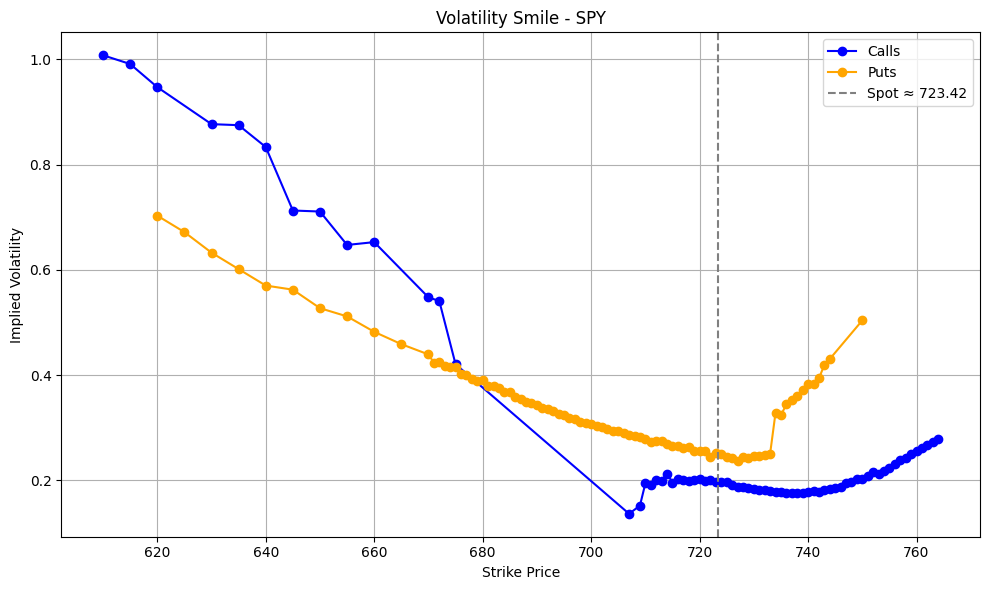

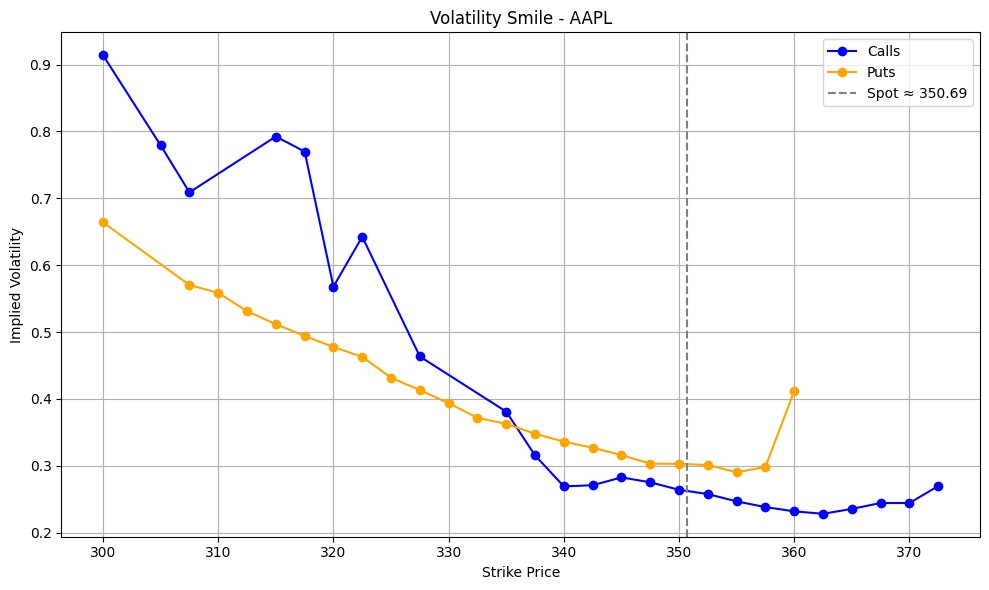

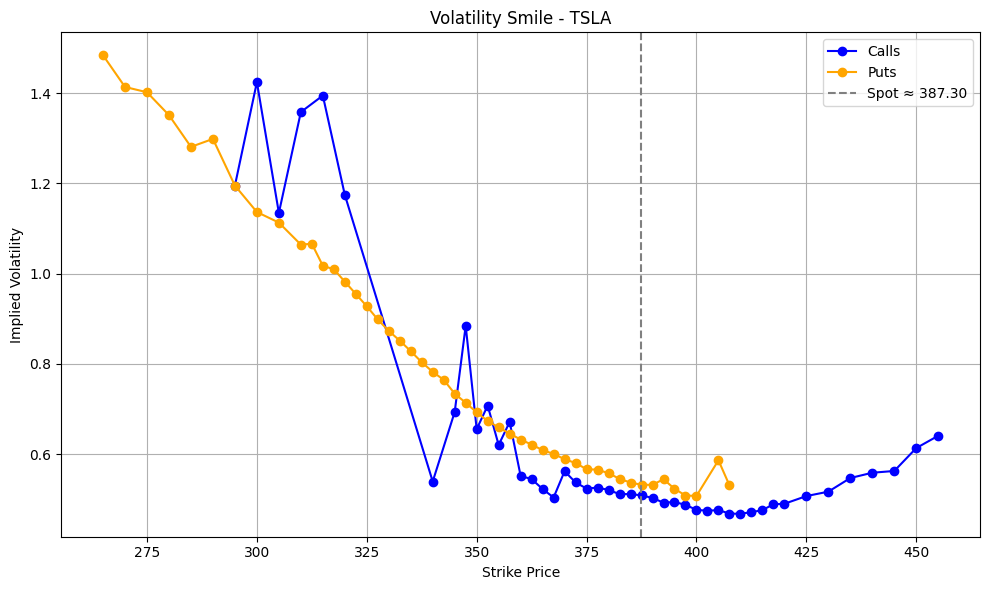

In [6]:
# Function to keep only liquid usable options
def liquid(df):
    return df[
        (df['impliedVolatility'] > 0.01) & (df['impliedVolatility'] < 1.5) & 
        (df['volume'] > 0) &                                                 
        (df['bid'] > 0) & (df['ask'] > 0) &                                   
        (df['openInterest'] > 10)                                            
    ].copy()

def clean_options(df):
    # Quote filter for the cleaned smile: plausible IV, valid two-sided quote, enough open interest
    # (no volume filter here, unlike liquid(), so more strikes survive)
    return df[
        (df['impliedVolatility'] > 0.01) &
        (df['impliedVolatility'] < 1.5) &
        (df['bid'] > 0) &
        (df['ask'] > 0) &
        (df['openInterest'] > 10)
    ].copy()

for ticker in assets:
    stock = yf.Ticker(ticker)

    # Step 1: choose expiration
    expiration = stock.options[1]
    option_chain = stock.option_chain(expiration)

    # Step 2: spot price
    spot = stock.history(period="1d")["Close"].iloc[-1]

    # Step 3: calls & puts
    calls = option_chain.calls
    puts = option_chain.puts

    # Step 4: filtering
    filtered_calls = liquid(calls).sort_values('strike')
    filtered_puts  = liquid(puts).sort_values('strike')

    # Step 5: plot (one figure per asset)
    plt.figure(figsize=(10, 6))

    plt.plot(
        filtered_calls['strike'],
        filtered_calls['impliedVolatility'],
        '-o',
        label="Calls",
        color='blue'
    )

    plt.plot(
        filtered_puts['strike'],
        filtered_puts['impliedVolatility'],
        '-o',
        label="Puts",
        color='orange'
    )

    plt.axvline(
        spot,
        color='gray',
        linestyle='--',
        label=f"Spot ≈ {spot:.2f}"
    )

    # Step 7: plot settings
    plt.title(f"Volatility Smile - {ticker}")
    plt.xlabel("Strike Price")
    plt.ylabel("Implied Volatility")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.show()

---
## CLEANED VISUALIZATION OF THE VOLATILITY SMILE
---

To plot a clean volatility smile, filters on IV, volumes and prices are not enough. 
It is important to keep only meaningful options. 
We only keep OTM options to avoid duplicating the same information, they already contain all the useful market information.
A call and a put with the same strike are linked by the put-call parity. 
Thus, an ITM calls and OTM put hold the same information, and so does an ITM out and an OTM call.

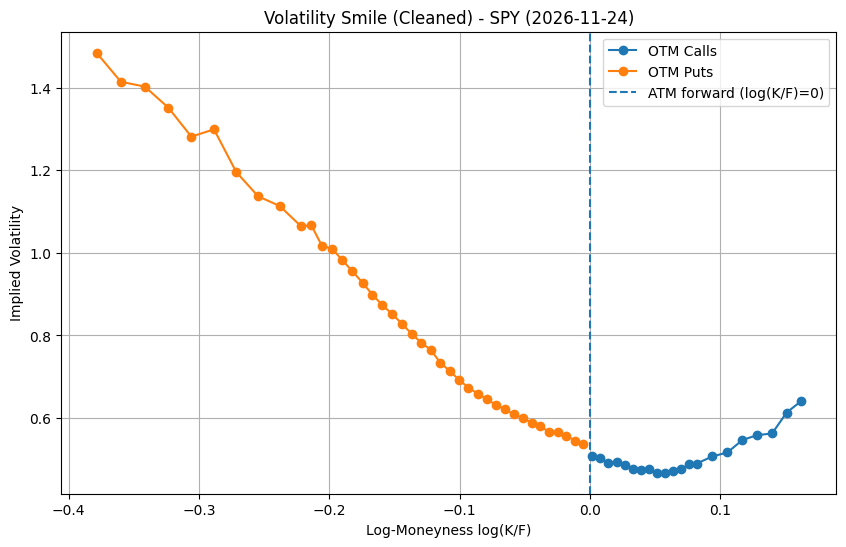

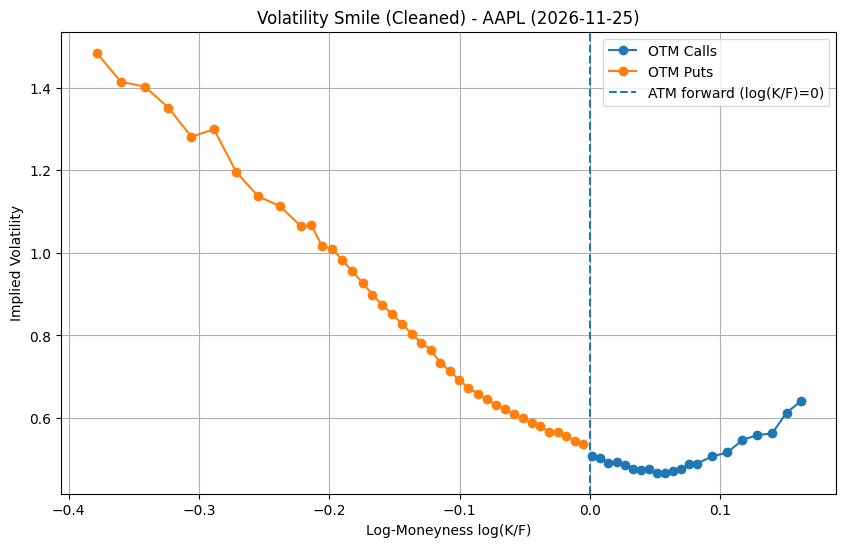

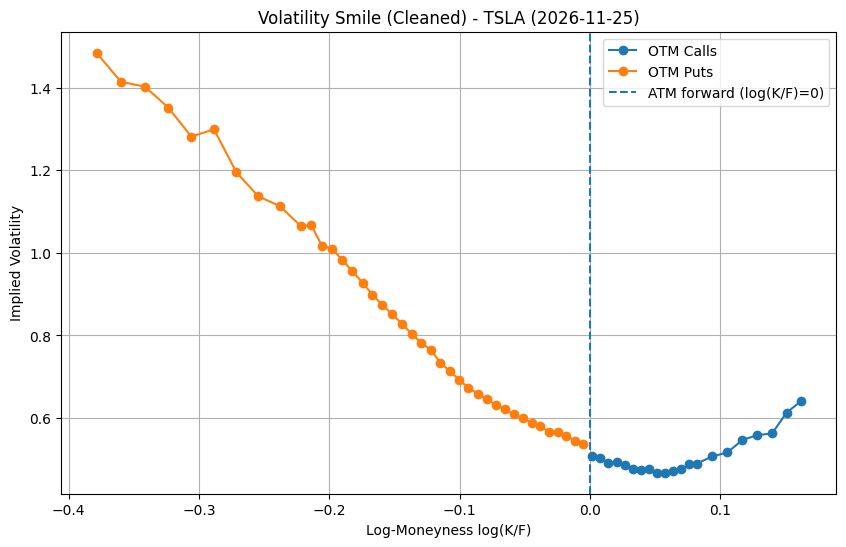

In [7]:
# Function to compute time to expiry in years
def year_fraction(expiration):
    exp = pd.Timestamp(expiration) + pd.Timedelta(hours=16)   # expiry = US market close at 4pm
    return (exp - pd.Timestamp.now()).total_seconds() / (365 * 86400)

# Function to estimate the forward F from put-call parity: C - P = e^{-rT} (F - K)
def implied_forward(calls, puts, T, r):
    m = calls.merge(puts, on='strike', suffixes=('_c', '_p'))                   
    m['diff'] = (m['bid_c'] + m['ask_c']) / 2 - (m['bid_p'] + m['ask_p']) / 2  
    k = m.loc[m['diff'].abs().idxmin()]                                       
    return k['strike'] + np.exp(r * T) * k['diff']  

for ticker in assets:
    stock = yf.Ticker(ticker)

    expiration = stock.options[1]
    option_chain = stock.option_chain(expiration)

    spot = stock.history(period="1d")["Close"].iloc[-1]   
    T = year_fraction(expiration)                      
    
    calls = clean_options(option_chain.calls.copy())
    puts  = clean_options(option_chain.puts.copy())
    F = implied_forward(calls, puts, T, r=0.04)  
    
    calls['log_moneyness'] = np.log(calls['strike'] / F) 
    puts['log_moneyness']  = np.log(puts['strike'] / F)   
    
    calls_otm = calls[calls['strike'] >= F]             
    puts_otm  = puts[puts['strike'] <= F]  

    calls_otm = calls_otm.sort_values(by='log_moneyness')
    puts_otm = puts_otm.sort_values(by='log_moneyness')

    plt.figure(figsize=(10, 6))
    plt.plot(
        calls_otm['log_moneyness'],
        calls_otm['impliedVolatility'],
        'o-',
        label='OTM Calls'
    )

    plt.plot(
        puts_otm['log_moneyness'],
        puts_otm['impliedVolatility'],
        'o-',
        label='OTM Puts'
    )

    plt.axvline(0, linestyle='--', label='ATM forward (log(K/F)=0)')
    plt.title(f"Volatility Smile (Cleaned) - {ticker} ({expiration})")
    plt.xlabel("Log-Moneyness log(K/F)") 
    plt.ylabel("Implied Volatility")
    plt.legend()
    plt.grid(True)

    plt.show()

The 3 plots above suggest that the volatility smile is not symmetric. This is the skew. They also suggest that deep OTM puts have much higher iv than OTM calls.

---
## FROM OBSERVATIONS TO MODELS
---

The SABR Model was designed to explain and reproduce the volatility smile observed in the market.

SABR assumes that not only asset prices but also volatility move randomly, though both are linked.
- dF=σ(F**β)dW
- dσ=νσdZ
- dW and dZ are correlated

SABR has 4 parameters being :
- α : controls the level of the volatility
- β : controls the shape of the smile
- correlation ρ : controls the assymetry of the smile
- volatility of volatility ν : controls how much the volatility moves

With the appropriate parameters, the iv predicted by SABR matches the observed iv.

Let's :
1. Define a SABR function (using the Hagan  approximation formula) to compute the theoretical iv using the 4 parameters.
2. Find the parameters such that the SABR predictions fit the market data best.
3. Compute theoretical iv using theses parameters and plot the curve on the market data.

In [8]:
# This function computes the implied volatility predicted by SABR
def sabr_implied_vol(F, K, T, alpha, beta, rho, nu):

    # ATM case handled separately, with a tolerance
    if abs(np.log(F / K)) < 1e-8:
        term1 = alpha / (F**(1 - beta)) # Base vol level
        term2 = (
            ((1 - beta)**2 / 24) * (alpha**2 / (F**(2 - 2*beta))) +
            (rho * beta * nu * alpha) / (4 * (F**(1 - beta))) +
            (nu**2 * (2 - 3*rho**2) / 24)
        ) * T # Correction term depending on time and parameters
        return term1 * (1 + term2)

    # General case K != F
    logFK = np.log(F / K) # Log-moneyness
    FK_beta = (F * K)**((1 - beta) / 2) 
    z = (nu / alpha) * FK_beta * logFK  
    x_z = np.log((np.sqrt(1 - 2*rho*z + z**2) + z - rho) / (1 - rho))

    term1 = alpha / (FK_beta * (1 + ((1 - beta)**2 / 24) * logFK**2)) # Base level
    term2 = z / x_z # Skew component
    term3 = 1 + (
        ((1 - beta)**2 / 24) * (alpha**2 / (FK_beta**2)) +
        (rho * beta * nu * alpha) / (4 * FK_beta) +
        (nu**2 * (2 - 3*rho**2) / 24)
    ) * T # Correction term depending on time and parameters
    return term1 * term2 * term3

# This function measures how well SABR fits the market
def sabr_loss(params, F, K, T, market_iv, beta):

    alpha, rho, nu = params

    if alpha <= 0 or nu <= 0 or abs(rho) >= 1: # Ensures parameters are valid
        return 1e10

    model_iv = np.array([
        sabr_implied_vol(F, k, T, alpha, beta, rho, nu)
        for k in K
    ]) # SABR volatility computed for each strike

    return np.mean((model_iv - market_iv)**2) # Mean squared error


SPY | F=723.33, T=0.0022 | alpha=6.6327, rho=-0.7781, nu=5.0000 | RMSE=0.0328 | success=True | nu*sqrt(T)=0.24


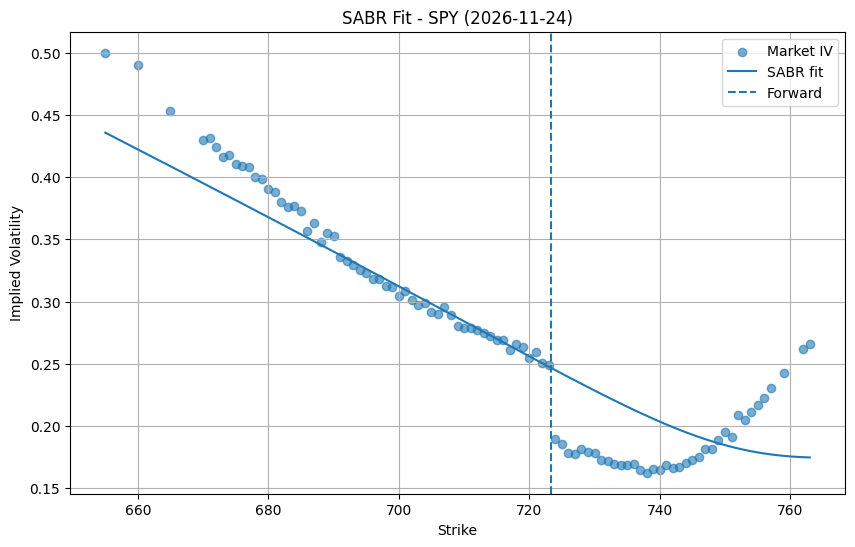

AAPL | F=350.53, T=0.0050 | alpha=5.4278, rho=-0.7026, nu=5.0000 | RMSE=0.0186 | success=True | nu*sqrt(T)=0.35


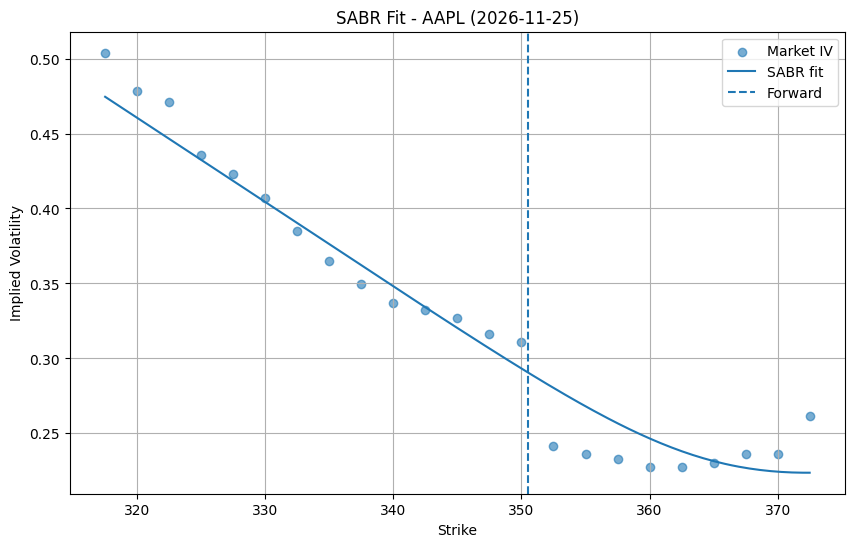

TSLA | F=386.75, T=0.0050 | alpha=10.2888, rho=-0.5700, nu=5.0000 | RMSE=0.0242 | success=True | nu*sqrt(T)=0.35


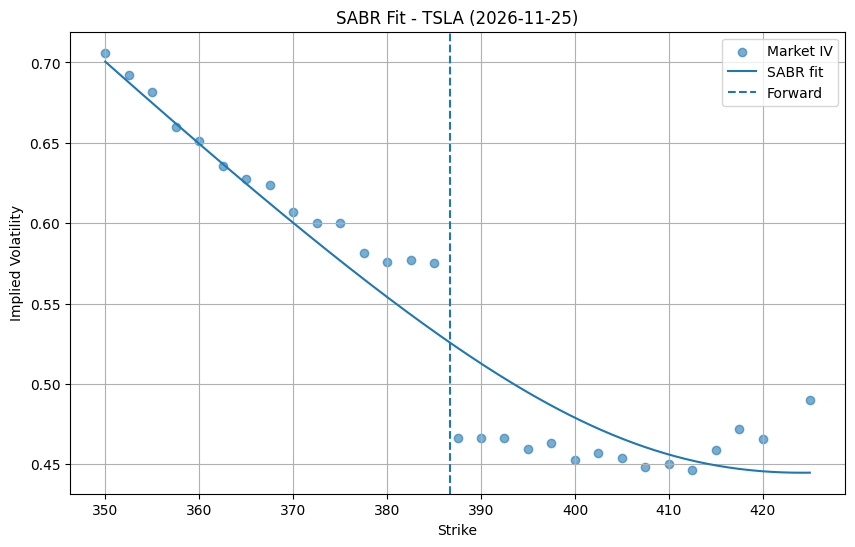

In [9]:
def clean(df):
    # Filter for the SABR fit
    df = df[
        (df['impliedVolatility'] > 0.01) &
        (df['impliedVolatility'] < 1.5) &
        (df['bid'] > 0) &
        (df['ask'] > 0) &
        (df['openInterest'] > 10)
    ].copy()

    df['mid'] = (df['bid'] + df['ask']) / 2  # Mid price
    df = df[df['mid'] > 0]

    return df

R = 0.04      # Assumed risk-free rate used to extract the forward from put-call parity
beta = 0.5    # beta is fixed

for ticker in assets:

    # Data is prepared as in the previous section
    stock = yf.Ticker(ticker)

    expiration = stock.options[1]
    option_chain = stock.option_chain(expiration)

    T = year_fraction(expiration)                           
    if T <= 0:                          
        print(f"{ticker}: expiry {expiration} too close, skipping")
        continue

    calls = clean(option_chain.calls.copy())
    puts = clean(option_chain.puts.copy())
    F = implied_forward(calls, puts, T, R)

    calls_otm = calls[calls['strike'] >= F]
    puts_otm = puts[puts['strike'] <= F]

    K = np.concatenate([puts_otm['strike'], calls_otm['strike']])
    iv = np.concatenate([puts_otm['impliedVolatility'], calls_otm['impliedVolatility']])

    idx = np.argsort(K)     
    K = K[idx]
    iv = iv[idx]

    mask = np.abs(np.log(K / F)) < 0.1    
    K, iv = K[mask], iv[mask]                    

    # The goal is then to find the best calibration parameters for the SABR model to match real data
    iv_atm = np.interp(F, K, iv)                
    initial_guess = [iv_atm * F**(1 - beta), -0.3, 1.0] # Starting points
    result = minimize( # Find parameters that minimize the loss function
        sabr_loss,
        initial_guess,
        args=(F, K, T, iv, beta), # Fixed inputs
        method='Nelder-Mead', # Trial-and-error search algorithm
        bounds=[(1e-4, None), (-0.999, 0.999), (1e-4, 5)] 
    )

    alpha, rho, nu = result.x

    print(
        f"{ticker} | F={F:.2f}, T={T:.4f} | "
        f"alpha={alpha:.4f}, rho={rho:.4f}, nu={nu:.4f} | "
        f"RMSE={np.sqrt(result.fun):.4f} | "          
        f"success={result.success} | "        
        f"nu*sqrt(T)={nu*np.sqrt(T):.2f}"   
    )

    # Compute the SABR model using these parameters
    K_grid = np.linspace(min(K), max(K), 200)

    sabr_iv = [
        sabr_implied_vol(F, k, T, alpha, beta, rho, nu)
        for k in K_grid
    ]

    # Plot
    plt.figure(figsize=(10, 6))

    plt.scatter(K, iv, label="Market IV", alpha=0.6)  
    plt.plot(K_grid, sabr_iv, label="SABR fit")      

    plt.axvline(F, linestyle='--', label="Forward") 

    plt.title(f"SABR Fit - {ticker} ({expiration})")
    plt.xlabel("Strike")
    plt.ylabel("Implied Volatility")
    plt.legend()
    plt.grid(True)

    plt.show()